In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "timeSeries").exists() and ROOT.name == "timeSeries":
    ROOT = ROOT.parent

RESULT_DIR = ROOT / "timeSeries/results/model_2_rolling"
PRED_PATH = RESULT_DIR / "rolling_origin_predictions.csv"
OUT_DIR = RESULT_DIR / "error_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PRED_PATH, parse_dates=["pickup_hour"])

df["error"] = df["predicted"] - df["actual"]
df["absolute_error"] = df["error"].abs()
df["squared_error"] = df["error"] ** 2
df["date"] = df["pickup_hour"].dt.date
df["hour"] = df["pickup_hour"].dt.hour
df["day_name"] = df["pickup_hour"].dt.day_name()

fold3 = df[df["fold"] == 3].copy()

print("Fold 3:", fold3["pickup_hour"].min(), "to", fold3["pickup_hour"].max())
print("Rows:", len(fold3))

Fold 3: 2026-02-16 21:00:00 to 2026-02-23 20:00:00
Rows: 23184


,MAE,RMSE,Mean signed error,Median absolute error,90th percentile absolute error,95th percentile absolute error,Maximum absolute error,Zero actual rows
0,13.647745,34.603668,8.390348,1.927247,39.402835,64.86184,452.996072,6697


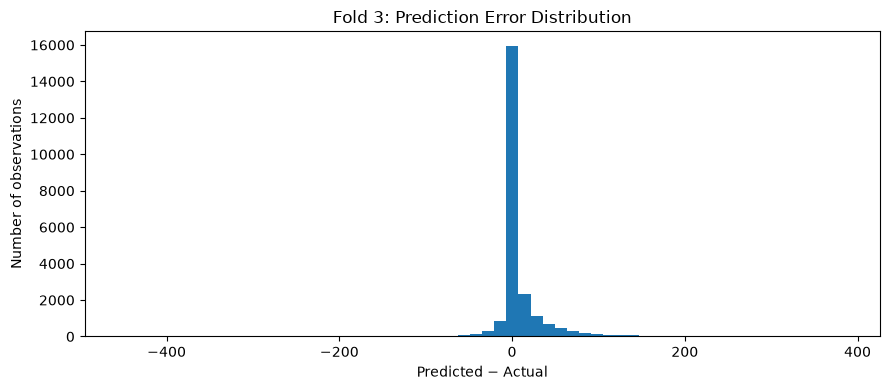

In [10]:
summary = pd.DataFrame([{
    "MAE": fold3["absolute_error"].mean(),
    "RMSE": np.sqrt(fold3["squared_error"].mean()),
    "Mean signed error": fold3["error"].mean(),
    "Median absolute error": fold3["absolute_error"].median(),
    "90th percentile absolute error": fold3["absolute_error"].quantile(0.90),
    "95th percentile absolute error": fold3["absolute_error"].quantile(0.95),
    "Maximum absolute error": fold3["absolute_error"].max(),
    "Zero actual rows": (fold3["actual"] == 0).sum()
}])

display(summary)

plt.figure(figsize=(9, 4))
plt.hist(fold3["error"], bins=60)
plt.title("Fold 3: Prediction Error Distribution")
plt.xlabel("Predicted − Actual")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

,date,n_rows,MAE,mean_error,RMSE
7,2026-02-23,2898,25.471542,24.674852,61.310596
6,2026-02-22,3312,19.862929,11.872019,46.682152
5,2026-02-21,3312,13.706861,4.417578,31.498943
2,2026-02-18,3312,10.086715,4.105554,22.591470
0,2026-02-16,414,10.073481,6.811400,22.504898
3,2026-02-19,3312,9.537346,4.983405,21.280486
1,2026-02-17,3312,9.416359,6.118672,22.014745
4,2026-02-20,3312,9.377220,4.793284,20.252981


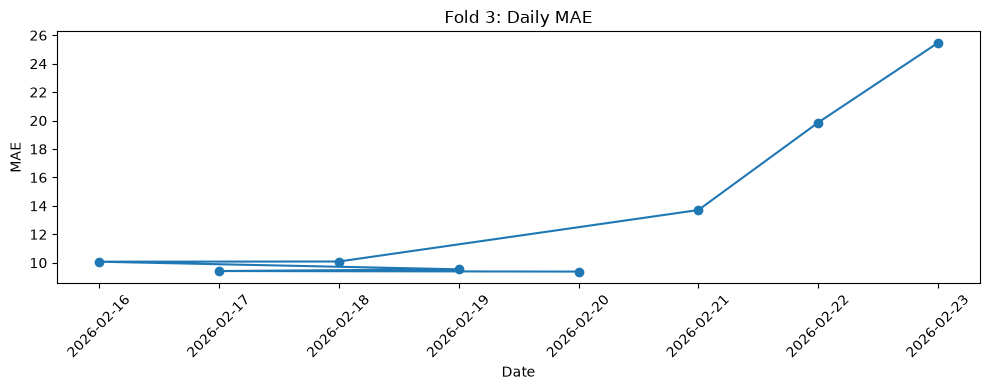

In [11]:
daily = (
    fold3.groupby("date")
    .agg(
        n_rows=("actual", "size"),
        MAE=("absolute_error", "mean"),
        mean_error=("error", "mean"),
        RMSE=("squared_error", lambda x: np.sqrt(x.mean()))
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

display(daily)
daily.to_csv(OUT_DIR / "fold3_daily_errors.csv", index=False)

plt.figure(figsize=(10, 4))
plt.plot(pd.to_datetime(daily["date"]), daily["MAE"], marker="o")
plt.title("Fold 3: Daily MAE")
plt.xlabel("Date")
plt.ylabel("MAE")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
zone_errors = (
    fold3.groupby("PULocationID")
    .agg(
        n_rows=("actual", "size"),
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
        mean_error=("error", "mean")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

display(zone_errors.head(20))
zone_errors.to_csv(OUT_DIR / "fold3_zone_errors.csv", index=False)

,PULocationID,n_rows,MAE,RMSE,mean_error
84,161,168,76.456691,115.043544,42.359429
123,236,168,74.024604,109.334443,52.868110
124,237,168,73.478139,112.092935,57.994846
31,79,168,73.392156,110.873093,19.430997
64,132,168,70.290759,118.290923,53.089102
72,142,168,61.745279,88.501154,37.655244
95,186,168,58.171072,80.616234,43.625664
85,162,168,56.134136,79.586871,37.858578
130,249,168,54.076222,77.665414,19.385934
118,230,168,53.946771,73.254873,33.965285


,hour,MAE,RMSE,mean_error
0,0,17.653793,41.512937,6.609792
1,1,14.454825,39.843934,4.467901
2,2,9.626680,28.943176,1.586749
3,3,6.239304,17.929607,-0.086167
4,4,4.418577,9.716313,0.342221
5,5,5.302521,11.585148,3.228688
6,6,8.176653,16.742816,5.288990
7,7,10.857024,22.970247,6.312672
8,8,13.094446,27.713331,6.305304
9,9,12.912093,28.788748,8.786604


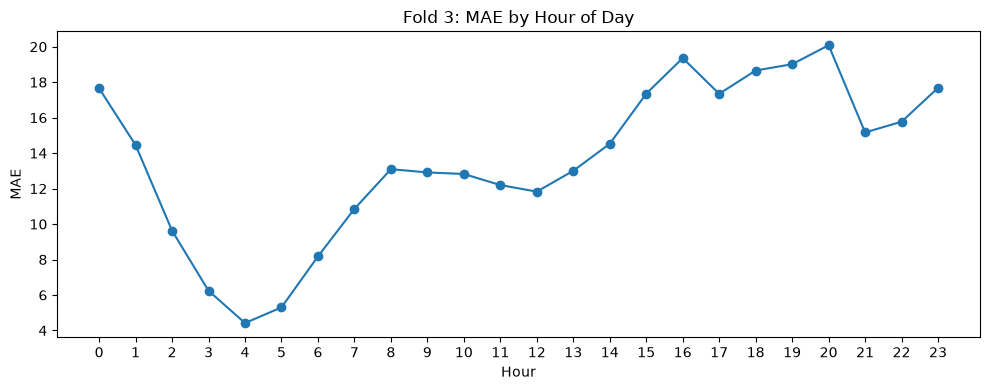

In [13]:
hour_errors = (
    fold3.groupby("hour")
    .agg(
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
        mean_error=("error", "mean")
    )
    .reset_index()
)

display(hour_errors)

plt.figure(figsize=(10, 4))
plt.plot(hour_errors["hour"], hour_errors["MAE"], marker="o")
plt.xticks(range(24))
plt.title("Fold 3: MAE by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()

hour_errors.to_csv(OUT_DIR / "fold3_hourly_errors.csv", index=False)

In [14]:
worst = fold3.assign(
    absolute_percentage_error=np.where(
        fold3["actual"] != 0,
        fold3["absolute_error"] / fold3["actual"].abs() * 100,
        np.nan
    )
).nlargest(30, "absolute_error")[
    [
        "PULocationID", "pickup_hour", "actual", "predicted",
        "error", "absolute_error", "absolute_percentage_error"
    ]
]

display(worst)
worst.to_csv(OUT_DIR / "fold3_top_errors.csv", index=False)

,PULocationID,pickup_hour,actual,predicted,error,absolute_error,absolute_percentage_error
51700,79,2026-02-22 01:00:00,814,361.003928,-452.996072,452.996072,55.650623
51699,79,2026-02-22 00:00:00,843,401.452180,-441.547820,441.547820,52.378152
51676,79,2026-02-21 01:00:00,749,340.630717,-408.369283,408.369283,54.521934
67362,237,2026-02-23 15:00:00,50,434.156292,384.156292,384.156292,768.312585
51701,79,2026-02-22 02:00:00,678,299.107300,-378.892700,378.892700,55.883879
60646,161,2026-02-23 19:00:00,85,462.575983,377.575983,377.575983,444.207039
57283,132,2026-02-23 16:00:00,10,383.502171,373.502171,373.502171,3735.021714
67195,236,2026-02-23 16:00:00,61,432.720774,371.720774,371.720774,609.378318
57284,132,2026-02-23 17:00:00,4,374.852192,370.852192,370.852192,9271.304794
57287,132,2026-02-23 20:00:00,2,371.223387,369.223387,369.223387,18461.169359


In [15]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(fold3.head(10))

print("\nData types:")
print(df.dtypes)

print("\nFold 3 location ID summary:")
print(df.loc[
    df["fold"] == 3, "PULocationID"
].describe())

Columns:
['fold', 'PULocationID', 'pickup_hour', 'actual', 'predicted', 'error', 'absolute_error', 'squared_error', 'date', 'hour', 'day_name']

First 10 rows:


,fold,PULocationID,pickup_hour,actual,predicted,error,absolute_error,squared_error,date,hour,day_name
46368,3,2,2026-02-16 21:00:00,0,0.005867,0.005867,0.005867,3.441997e-05,2026-02-16,21,Monday
46369,3,2,2026-02-16 22:00:00,0,0.004563,0.004563,0.004563,2.082265e-05,2026-02-16,22,Monday
46370,3,2,2026-02-16 23:00:00,0,0.005350,0.005350,0.005350,2.862360e-05,2026-02-16,23,Monday
46371,3,2,2026-02-17 00:00:00,0,0.006809,0.006809,0.006809,4.636656e-05,2026-02-17,0,Tuesday
46372,3,2,2026-02-17 01:00:00,0,0.007278,0.007278,0.007278,5.296809e-05,2026-02-17,1,Tuesday
46373,3,2,2026-02-17 02:00:00,0,0.005877,0.005877,0.005877,3.454167e-05,2026-02-17,2,Tuesday
46374,3,2,2026-02-17 03:00:00,0,0.003113,0.003113,0.003113,9.689623e-06,2026-02-17,3,Tuesday
46375,3,2,2026-02-17 04:00:00,0,0.000622,0.000622,0.000622,3.874604e-07,2026-02-17,4,Tuesday
46376,3,2,2026-02-17 05:00:00,0,0.000203,0.000203,0.000203,4.106231e-08,2026-02-17,5,Tuesday
46377,3,2,2026-02-17 06:00:00,0,0.002687,0.002687,0.002687,7.222345e-06,2026-02-17,6,Tuesday



Data types:
fold                       int64
PULocationID               int64
pickup_hour       datetime64[us]
actual                     int64
predicted                float64
error                    float64
absolute_error           float64
squared_error            float64
date                      object
hour                       int32
day_name                     str
dtype: object

Fold 3 location ID summary:
count    23184.000000
mean       138.000000
std         73.082928
min          2.000000
25%         86.000000
50%        138.500000
75%        201.000000
max        263.000000
Name: PULocationID, dtype: float64


In [16]:
# Recalculate errors to ensure consistency
fold3 = df.loc[df["fold"] == 3].copy()

fold3["error"] = fold3["predicted"] - fold3["actual"]
fold3["absolute_error"] = fold3["error"].abs()

# Largest absolute errors
worst30 = fold3.nlargest(30, "absolute_error")[
    [
        "PULocationID",
        "pickup_hour",
        "actual",
        "predicted",
        "error",
        "absolute_error"
    ]
].copy()

worst30["date"] = worst30["pickup_hour"].dt.date
worst30["hour"] = worst30["pickup_hour"].dt.hour

display(worst30)

,PULocationID,pickup_hour,actual,predicted,error,absolute_error,date,hour
51700,79,2026-02-22 01:00:00,814,361.003928,-452.996072,452.996072,2026-02-22,1
51699,79,2026-02-22 00:00:00,843,401.452180,-441.547820,441.547820,2026-02-22,0
51676,79,2026-02-21 01:00:00,749,340.630717,-408.369283,408.369283,2026-02-21,1
67362,237,2026-02-23 15:00:00,50,434.156292,384.156292,384.156292,2026-02-23,15
51701,79,2026-02-22 02:00:00,678,299.107300,-378.892700,378.892700,2026-02-22,2
60646,161,2026-02-23 19:00:00,85,462.575983,377.575983,377.575983,2026-02-23,19
57283,132,2026-02-23 16:00:00,10,383.502171,373.502171,373.502171,2026-02-23,16
67195,236,2026-02-23 16:00:00,61,432.720774,371.720774,371.720774,2026-02-23,16
57284,132,2026-02-23 17:00:00,4,374.852192,370.852192,370.852192,2026-02-23,17
57287,132,2026-02-23 20:00:00,2,371.223387,369.223387,369.223387,2026-02-23,20


In [17]:
print("Total Fold 3 observations:", len(fold3))
print("Zero actual demand:", (fold3["actual"] == 0).sum())

print(
    "Zero actual but positive prediction:",
    (
        (fold3["actual"] == 0) &
        (fold3["predicted"] > 0)
    ).sum()
)

print("\nWorst errors where actual demand is zero:")
display(
    fold3.loc[fold3["actual"] == 0]
    .nlargest(10, "absolute_error")[
        [
            "PULocationID",
            "pickup_hour",
            "actual",
            "predicted",
            "error",
            "absolute_error"
        ]
    ]
)

print("\nWorst errors where actual demand is positive:")
display(
    fold3.loc[fold3["actual"] > 0]
    .nlargest(10, "absolute_error")[
        [
            "PULocationID",
            "pickup_hour",
            "actual",
            "predicted",
            "error",
            "absolute_error"
        ]
    ]
)

Total Fold 3 observations: 23184
Zero actual demand: 6697
Zero actual but positive prediction: 6045

Worst errors where actual demand is zero:


,PULocationID,pickup_hour,actual,predicted,error,absolute_error
57953,138,2026-02-23 14:00:00,0,256.148580,256.148580,256.148580
57954,138,2026-02-23 15:00:00,0,254.531190,254.531190,254.531190
57952,138,2026-02-23 13:00:00,0,247.846665,247.846665,247.846665
57955,138,2026-02-23 16:00:00,0,244.847850,244.847850,244.847850
57951,138,2026-02-23 12:00:00,0,231.243683,231.243683,231.243683
57936,138,2026-02-22 21:00:00,0,225.335707,225.335707,225.335707
57959,138,2026-02-23 20:00:00,0,219.617999,219.617999,219.617999
57958,138,2026-02-23 19:00:00,0,218.989027,218.989027,218.989027
57937,138,2026-02-22 22:00:00,0,215.924858,215.924858,215.924858
57950,138,2026-02-23 11:00:00,0,209.552164,209.552164,209.552164



Worst errors where actual demand is positive:


,PULocationID,pickup_hour,actual,predicted,error,absolute_error
51700,79,2026-02-22 01:00:00,814,361.003928,-452.996072,452.996072
51699,79,2026-02-22 00:00:00,843,401.452180,-441.547820,441.547820
51676,79,2026-02-21 01:00:00,749,340.630717,-408.369283,408.369283
67362,237,2026-02-23 15:00:00,50,434.156292,384.156292,384.156292
51701,79,2026-02-22 02:00:00,678,299.107300,-378.892700,378.892700
60646,161,2026-02-23 19:00:00,85,462.575983,377.575983,377.575983
57283,132,2026-02-23 16:00:00,10,383.502171,373.502171,373.502171
67195,236,2026-02-23 16:00:00,61,432.720774,371.720774,371.720774
57284,132,2026-02-23 17:00:00,4,374.852192,370.852192,370.852192
57287,132,2026-02-23 20:00:00,2,371.223387,369.223387,369.223387


In [18]:
# Count extreme errors by date
print("Worst 30 errors by date:")
display(
    worst30.groupby("date")
    .agg(
        count=("absolute_error", "size"),
        mean_abs_error=("absolute_error", "mean"),
        max_abs_error=("absolute_error", "max")
    )
    .sort_values("count", ascending=False)
)

# Count extreme errors by pickup zone
print("Worst 30 errors by pickup zone:")
display(
    worst30.groupby("PULocationID")
    .agg(
        count=("absolute_error", "size"),
        mean_abs_error=("absolute_error", "mean"),
        max_abs_error=("absolute_error", "max")
    )
    .sort_values("count", ascending=False)
)

Worst 30 errors by date:


,count,mean_abs_error,max_abs_error
date,,,
2026-02-23,22,357.535957,384.156292
2026-02-22,6,383.023678,452.996072
2026-02-20,1,335.377679,335.377679
2026-02-21,1,408.369283,408.369283


Worst 30 errors by pickup zone:


,count,mean_abs_error,max_abs_error
PULocationID,,,
132,10,355.740467,373.502171
237,7,352.524683,384.156292
79,4,420.451469,452.996072
161,4,362.402248,377.575983
236,4,353.952523,371.720774
142,1,335.377679,335.377679


In [19]:
import pandas as pd
import numpy as np

# Use the existing Fold 3 subset
fold3 = df.loc[df["fold"] == 3].copy()

fold3["error"] = fold3["predicted"] - fold3["actual"]
fold3["absolute_error"] = fold3["error"].abs()

zones_to_check = [79, 132, 237, 161]

zone_summary = (
    fold3[fold3["PULocationID"].isin(zones_to_check)]
    .groupby("PULocationID")
    .agg(
        observations=("actual", "size"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean"),
        MAE=("absolute_error", "mean"),
        mean_error=("error", "mean"),
        max_absolute_error=("absolute_error", "max")
    )
    .round(3)
)

display(zone_summary)

,observations,actual_mean,predicted_mean,MAE,mean_error,max_absolute_error
PULocationID,,,,,,
79,168,123.381,142.812,73.392,19.431,452.996
132,168,154.208,207.297,70.291,53.089,373.502
161,168,178.137,220.496,76.457,42.359,377.576
237,168,183.304,241.298,73.478,57.995,384.156


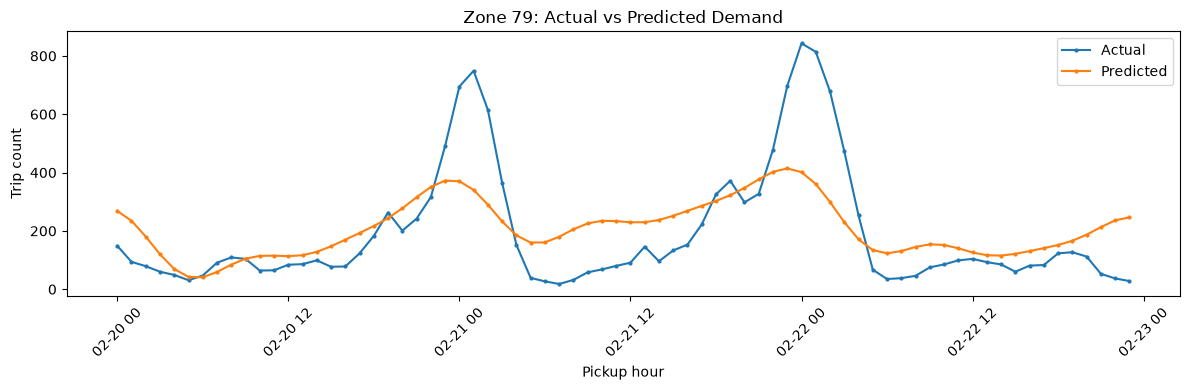

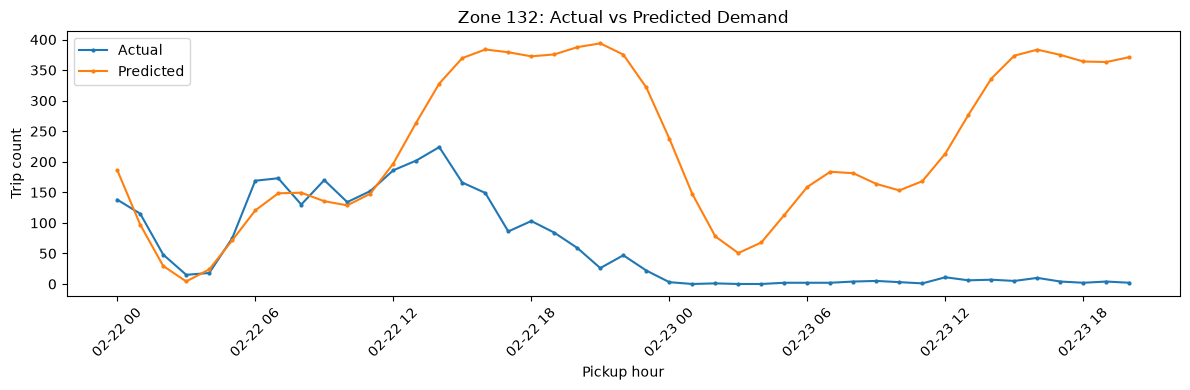

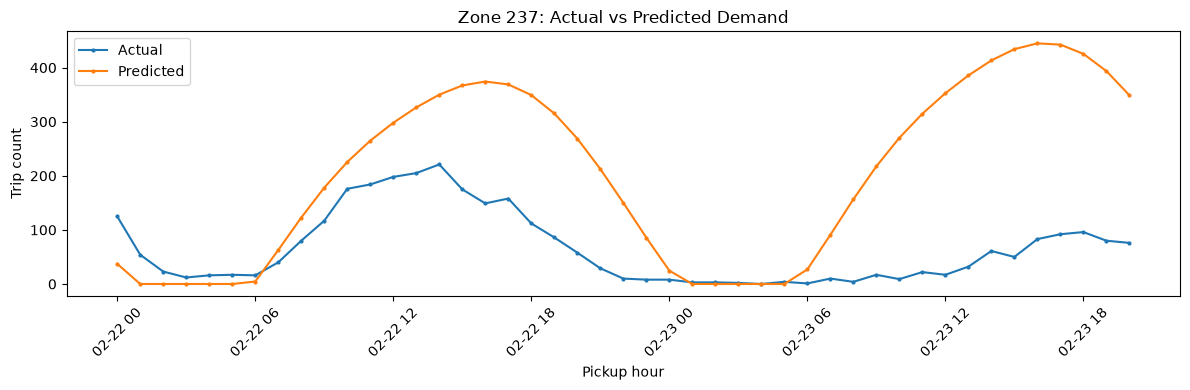

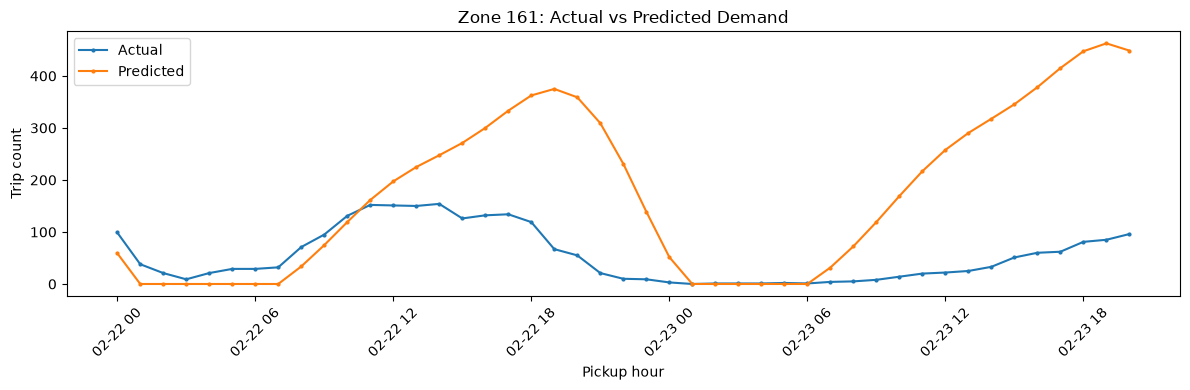

In [20]:
import matplotlib.pyplot as plt

fold3["pickup_hour"] = pd.to_datetime(fold3["pickup_hour"])

inspection_windows = [
    (79, "2026-02-20", "2026-02-23"),
    (132, "2026-02-22", "2026-02-24"),
    (237, "2026-02-22", "2026-02-24"),
    (161, "2026-02-22", "2026-02-24"),
]

for zone, start, end in inspection_windows:
    subset = fold3[
        (fold3["PULocationID"] == zone)
        & (fold3["pickup_hour"] >= start)
        & (fold3["pickup_hour"] < end)
    ].sort_values("pickup_hour")

    if subset.empty:
        print(f"No observations found for zone {zone}")
        continue

    plt.figure(figsize=(12, 4))
    plt.plot(
        subset["pickup_hour"], subset["actual"],
        label="Actual", marker=".", markersize=4
    )
    plt.plot(
        subset["pickup_hour"], subset["predicted"],
        label="Predicted", marker=".", markersize=4
    )
    plt.title(f"Zone {zone}: Actual vs Predicted Demand")
    plt.xlabel("Pickup hour")
    plt.ylabel("Trip count")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [22]:
from pathlib import Path

# Locate the original processed dataset
features_path = Path("data/processed/features.csv")

if not features_path.exists():
    features_path = Path("../data/processed/features.csv")

if not features_path.exists():
    raise FileNotFoundError(
        "Could not find data/processed/features.csv. "
        "Run this notebook from the project root or update features_path."
    )

features = pd.read_csv(
    features_path,
    parse_dates=["pickup_hour"]
)

features["pickup_hour"] = pd.to_datetime(features["pickup_hour"])
fold3["pickup_hour"] = pd.to_datetime(fold3["pickup_hour"])

# Select the worst observations
worst30 = fold3.nlargest(30, "absolute_error").copy()

# Confirm original dataset contains the expected keys
keys = ["PULocationID", "pickup_hour"]

print("Duplicate zone-hour rows in original data:",
      features.duplicated(keys).sum())

print("Duplicate zone-hour rows in Fold 3:",
      fold3.duplicated(keys).sum())

# Match original observations with Fold 3 predictions
original = features[keys + ["trip_count"]].rename(
    columns={"trip_count": "original_actual"}
)

validation = worst30.merge(
    original,
    on=keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

validation["actual_matches_original"] = (
    validation["actual"] == validation["original_actual"]
)

display(
    validation[
        [
            "PULocationID", "pickup_hour",
            "actual", "original_actual",
            "predicted", "error",
            "actual_matches_original", "_merge"
        ]
    ]
)

print("\nMatch status:")
print(validation["_merge"].value_counts())

print("\nActual-value agreement:")
print(validation["actual_matches_original"].value_counts(dropna=False))

Duplicate zone-hour rows in original data: 0
Duplicate zone-hour rows in Fold 3: 0


,PULocationID,pickup_hour,actual,original_actual,predicted,error,actual_matches_original,_merge
0,79,2026-02-22 01:00:00,814,814,361.003928,-452.996072,True,both
1,79,2026-02-22 00:00:00,843,843,401.452180,-441.547820,True,both
2,79,2026-02-21 01:00:00,749,749,340.630717,-408.369283,True,both
3,237,2026-02-23 15:00:00,50,50,434.156292,384.156292,True,both
4,79,2026-02-22 02:00:00,678,678,299.107300,-378.892700,True,both
5,161,2026-02-23 19:00:00,85,85,462.575983,377.575983,True,both
6,132,2026-02-23 16:00:00,10,10,383.502171,373.502171,True,both
7,236,2026-02-23 16:00:00,61,61,432.720774,371.720774,True,both
8,132,2026-02-23 17:00:00,4,4,374.852192,370.852192,True,both
9,132,2026-02-23 20:00:00,2,2,371.223387,369.223387,True,both



Match status:
_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64

Actual-value agreement:
actual_matches_original
True    30
Name: count, dtype: int64


In [21]:
print("Fold 3 observations:", len(fold3))
print("Unique zones:", fold3["PULocationID"].nunique())
print("Duplicate zone-hour rows:", fold3.duplicated(
    ["PULocationID", "pickup_hour"]
).sum())

print("\nMissing values:")
display(
    fold3[
        ["PULocationID", "pickup_hour", "actual", "predicted"]
    ].isna().sum()
)

print("\nNegative actual counts:", (fold3["actual"] < 0).sum())
print("Negative predictions:", (fold3["predicted"] < 0).sum())

Fold 3 observations: 23184
Unique zones: 138
Duplicate zone-hour rows: 0

Missing values:


PULocationID    0
pickup_hour     0
actual          0
predicted       0
dtype: int64


Negative actual counts: 0
Negative predictions: 0


In [23]:
import pandas as pd
from pathlib import Path

features_path = Path("data/processed/features.csv")
if not features_path.exists():
    features_path = Path("../data/processed/features.csv")

features = pd.read_csv(
    features_path,
    parse_dates=["pickup_hour"]
)

features["pickup_hour"] = pd.to_datetime(features["pickup_hour"])

zones = [79, 132, 161, 237]
start = pd.Timestamp("2026-02-20 00:00")
end = pd.Timestamp("2026-02-24 00:00")

historical = features[
    features["PULocationID"].isin(zones)
].copy()

historical["hour_of_week"] = (
    historical["pickup_hour"].dt.dayofweek * 24
    + historical["pickup_hour"].dt.hour
)

# Focus on the affected period
affected = historical[
    (historical["pickup_hour"] >= start)
    & (historical["pickup_hour"] < end)
].copy()

# Historical observations from the preceding four weeks
prior = historical[
    (historical["pickup_hour"] >= start - pd.Timedelta(days=28))
    & (historical["pickup_hour"] < start)
].copy()

weekly_reference = (
    prior.groupby(["PULocationID", "hour_of_week"])["trip_count"]
    .agg(
        historical_median="median",
        historical_mean="mean",
        historical_max="max"
    )
    .reset_index()
)

affected["hour_of_week"] = (
    affected["pickup_hour"].dt.dayofweek * 24
    + affected["pickup_hour"].dt.hour
)

comparison = affected.merge(
    weekly_reference,
    on=["PULocationID", "hour_of_week"],
    how="left",
    validate="many_to_one"
)

comparison["actual_vs_historical_median"] = (
    comparison["trip_count"] - comparison["historical_median"]
)

display(
    comparison[
        [
            "PULocationID",
            "pickup_hour",
            "trip_count",
            "historical_median",
            "historical_mean",
            "historical_max",
            "actual_vs_historical_median"
        ]
    ].sort_values(["PULocationID", "pickup_hour"])
)

,PULocationID,pickup_hour,trip_count,historical_median,historical_mean,historical_max,actual_vs_historical_median
0,79,2026-02-20 00:00:00,149,207.5,210.75,258,-58.5
1,79,2026-02-20 01:00:00,94,127.5,128.75,143,-33.5
2,79,2026-02-20 02:00:00,79,86.5,86.00,99,-7.5
3,79,2026-02-20 03:00:00,60,67.5,72.75,91,-7.5
4,79,2026-02-20 04:00:00,49,50.5,50.75,58,-1.5
...,...,...,...,...,...,...,...
379,237,2026-02-23 19:00:00,80,255.5,252.25,345,-175.5
380,237,2026-02-23 20:00:00,76,240.5,232.50,303,-164.5
381,237,2026-02-23 21:00:00,54,202.5,207.75,303,-148.5
382,237,2026-02-23 22:00:00,39,93.5,102.75,152,-54.5


In [24]:
# Summarize the affected period by zone
comparison["deviation"] = (
    comparison["trip_count"] - comparison["historical_median"]
)

zone_deviation = (
    comparison.groupby("PULocationID")
    .agg(
        observations=("trip_count", "size"),
        actual_mean=("trip_count", "mean"),
        historical_median_mean=("historical_median", "mean"),
        mean_deviation=("deviation", "mean"),
        mean_absolute_deviation=(
            "deviation",
            lambda x: x.abs().mean()
        ),
        above_historical_pct=(
            "deviation",
            lambda x: (x > 0).mean() * 100
        ),
        below_historical_pct=(
            "deviation",
            lambda x: (x < 0).mean() * 100
        )
    )
    .round(2)
)

display(zone_deviation.loc[[79, 132, 161, 237]])

,observations,actual_mean,historical_median_mean,mean_deviation,mean_absolute_deviation,above_historical_pct,below_historical_pct
PULocationID,,,,,,,
79,96,151.53,180.89,-29.35,44.43,20.83,79.17
132,96,119.34,178.50,-59.16,97.67,50.00,50.00
161,96,119.88,158.78,-38.90,60.03,31.25,67.71
237,96,142.41,191.54,-49.13,58.52,28.12,71.88


In [25]:
# Largest demand increases relative to historical median
print("Largest positive deviations:")
display(
    comparison.nlargest(10, "deviation")[
        [
            "PULocationID",
            "pickup_hour",
            "trip_count",
            "historical_median",
            "deviation"
        ]
    ]
)

# Largest demand decreases relative to historical median
print("Largest negative deviations:")
display(
    comparison.nsmallest(10, "deviation")[
        [
            "PULocationID",
            "pickup_hour",
            "trip_count",
            "historical_median",
            "deviation"
        ]
    ]
)

Largest positive deviations:


,PULocationID,pickup_hour,trip_count,historical_median,deviation
142,132,2026-02-21 22:00:00,369,219.0,150.0
49,79,2026-02-22 01:00:00,814,687.0,127.0
50,79,2026-02-22 02:00:00,678,553.0,125.0
48,79,2026-02-22 00:00:00,843,735.0,108.0
51,79,2026-02-22 03:00:00,473,369.5,103.5
302,237,2026-02-20 14:00:00,542,442.0,100.0
239,161,2026-02-21 23:00:00,262,166.5,95.5
205,161,2026-02-20 13:00:00,348,257.0,91.0
143,132,2026-02-21 23:00:00,272,184.0,88.0
206,161,2026-02-20 14:00:00,396,313.5,82.5


Largest negative deviations:


,PULocationID,pickup_hour,trip_count,historical_median,deviation
188,132,2026-02-23 20:00:00,2,398.0,-396.0
164,132,2026-02-22 20:00:00,59,430.0,-371.0
187,132,2026-02-23 19:00:00,4,363.0,-359.0
185,132,2026-02-23 17:00:00,4,356.5,-352.5
184,132,2026-02-23 16:00:00,10,359.5,-349.5
190,132,2026-02-23 22:00:00,0,340.5,-340.5
189,132,2026-02-23 21:00:00,2,342.0,-340.0
191,132,2026-02-23 23:00:00,2,341.0,-339.0
186,132,2026-02-23 18:00:00,2,330.5,-328.5
183,132,2026-02-23 15:00:00,5,332.5,-327.5


In [26]:
import pandas as pd

zones = [79, 132, 161, 237]

start = pd.Timestamp("2026-02-20 00:00")
end = pd.Timestamp("2026-02-24 00:00")

raw_check = features.loc[
    features["PULocationID"].isin(zones)
    & (features["pickup_hour"] >= start)
    & (features["pickup_hour"] < end),
    ["PULocationID", "pickup_hour", "trip_count"]
].copy()

# Check coverage and count continuity
print("Rows:", len(raw_check))
print("Unique zone-hour combinations:",
      raw_check[["PULocationID", "pickup_hour"]].drop_duplicates().shape[0])

print("\nHourly counts by zone:")
for zone in zones:
    z = raw_check[raw_check["PULocationID"] == zone].sort_values("pickup_hour")

    print(f"\nZone {zone}")
    print("Rows:", len(z))
    print("Missing hourly timestamps:",
          len(pd.date_range(start, end, freq="h", inclusive="left"))
          - z["pickup_hour"].nunique())
    display(z[["pickup_hour", "trip_count"]].tail(48))

Rows: 384
Unique zone-hour combinations: 384

Hourly counts by zone:

Zone 79
Rows: 96
Missing hourly timestamps: 0


,pickup_hour,trip_count
133464,2026-02-22 00:00:00,843
133465,2026-02-22 01:00:00,814
133466,2026-02-22 02:00:00,678
133467,2026-02-22 03:00:00,473
133468,2026-02-22 04:00:00,253
133469,2026-02-22 05:00:00,67
133470,2026-02-22 06:00:00,35
133471,2026-02-22 07:00:00,38
133472,2026-02-22 08:00:00,46
133473,2026-02-22 09:00:00,75



Zone 132
Rows: 96
Missing hourly timestamps: 0


,pickup_hour,trip_count
271272,2026-02-22 00:00:00,138
271273,2026-02-22 01:00:00,115
271274,2026-02-22 02:00:00,48
271275,2026-02-22 03:00:00,15
271276,2026-02-22 04:00:00,18
271277,2026-02-22 05:00:00,75
271278,2026-02-22 06:00:00,169
271279,2026-02-22 07:00:00,173
271280,2026-02-22 08:00:00,130
271281,2026-02-22 09:00:00,170



Zone 161
Rows: 96
Missing hourly timestamps: 0


,pickup_hour,trip_count
354792,2026-02-22 00:00:00,99
354793,2026-02-22 01:00:00,38
354794,2026-02-22 02:00:00,21
354795,2026-02-22 03:00:00,9
354796,2026-02-22 04:00:00,21
354797,2026-02-22 05:00:00,29
354798,2026-02-22 06:00:00,29
354799,2026-02-22 07:00:00,32
354800,2026-02-22 08:00:00,71
354801,2026-02-22 09:00:00,95



Zone 237
Rows: 96
Missing hourly timestamps: 0


,pickup_hour,trip_count
521832,2026-02-22 00:00:00,125
521833,2026-02-22 01:00:00,54
521834,2026-02-22 02:00:00,23
521835,2026-02-22 03:00:00,12
521836,2026-02-22 04:00:00,16
521837,2026-02-22 05:00:00,17
521838,2026-02-22 06:00:00,16
521839,2026-02-22 07:00:00,40
521840,2026-02-22 08:00:00,80
521841,2026-02-22 09:00:00,117
